In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
!wget https://raw.githubusercontent.com/databyhuseyn/DeepLearning/main/helper_functions.py

--2026-02-02 07:11:16--  https://raw.githubusercontent.com/databyhuseyn/DeepLearning/main/helper_functions.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10246 (10K) [text/plain]
Saving to: ‘helper_functions.py’

helper_functions.py 100%[===================>]  10.01K  --.-KB/s    in 0.001s  

2026-02-02 07:11:16 (8.03 MB/s) - ‘helper_functions.py’ saved [10246/10246]



In [4]:
from helper_functions import create_tensorboard_callback, plot_loss_curves,unzip_data,walk_through_dir

In [5]:
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/101_food_classes_10_percent.zip

--2026-02-02 07:11:27--  https://storage.googleapis.com/ztm_tf_course/food_vision/101_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.204.207, 172.217.203.207, 173.194.216.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.204.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1625420029 (1.5G) [application/zip]
Saving to: ‘101_food_classes_10_percent.zip’

101_food_classes_10 100%[===================>]   1.51G   199MB/s    in 8.5s    

2026-02-02 07:11:36 (182 MB/s) - ‘101_food_classes_10_percent.zip’ saved [1625420029/1625420029]



In [6]:
unzip_data("101_food_classes_10_percent.zip")

train_dir = "101_food_classes_10_percent/train/"
test_dir ="101_food_classes_10_percent/test/"

In [7]:
import tensorflow as tf
IMG_SIZE =(224,224)
batch_size =32

train_data_all_10_percent= tf.keras.preprocessing.image_dataset_from_directory(train_dir,
                                                                               image_size=IMG_SIZE,
                                                                               label_mode='categorical',
                                                                               batch_size=batch_size)

test_data_all_10_percent= tf.keras.preprocessing.image_dataset_from_directory(test_dir,
                                                                               image_size=IMG_SIZE,
                                                                               label_mode='categorical',
                                                                               shuffle=False)

Found 7575 files belonging to 101 classes.
Found 25250 files belonging to 101 classes.


In [8]:
walk_through_dir('/ontent/101_food_classes_10_percent')

In [9]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomHeight(0.2),
    tf.keras.layers.RandomWidth(0.2)
],name='data_augmentation')

In [10]:
base_model =tf.keras.applications.efficientnet_v2.EfficientNetV2B0(include_top=False)
base_model.trainable=False

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [11]:
input_shape = (224,224,3)
inputs = tf.keras.layers.Input(shape=input_shape, name='input_layer')
x=data_augmentation(inputs)
x=base_model(x,training=False)
x=tf.keras.layers.GlobalAveragePooling2D(name='global_average_pooling_layer')(x)
outputs = tf.keras.layers.Dense(len(train_data_all_10_percent.class_names),activation='softmax',name='output_layer')(x)

model_0 = tf.keras.Model(inputs,outputs)

In [12]:
model_0.compile(loss='categorical_crossentropy',
                optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                metrics=['accuracy'])

In [13]:
history_0=model_0.fit(train_data_all_10_percent,
                      epochs=5,
                      steps_per_epoch=int(len(train_data_all_10_percent)),
                      validation_data=test_data_all_10_percent,
                      validation_steps=int((0.25*len(test_data_all_10_percent))))

Epoch 1/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 105s 372ms/step - accuracy: 0.1344 - loss: 4.0827 - val_accuracy: 0.3447 - val_loss: 2.8617
Epoch 2/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 74s 311ms/step - accuracy: 0.4212 - loss: 2.5796 - val_accuracy: 0.4477 - val_loss: 2.3076
Epoch 3/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 66s 277ms/step - accuracy: 0.5063 - loss: 2.1550 - val_accuracy: 0.4665 - val_loss: 2.1032
Epoch 4/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 59s 251ms/step - accuracy: 0.5353 - loss: 1.9510 - val_accuracy: 0.5002 - val_loss: 1.9501
Epoch 5/5
237/237 ━━━━━━━━━━━━━━━━━━━━ 57s 239ms/step - accuracy: 0.5648 - loss: 1.8181 - val_accuracy: 0.5090 - val_loss: 1.9025


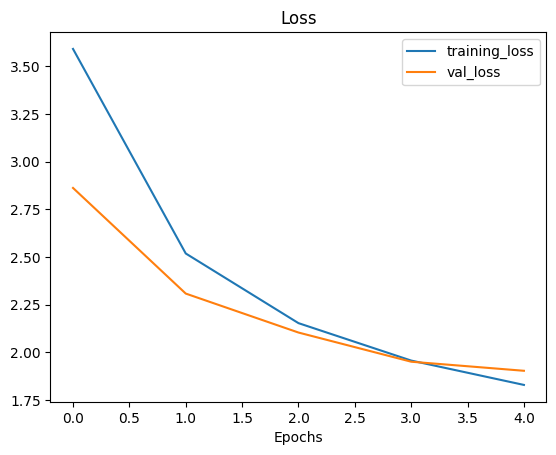

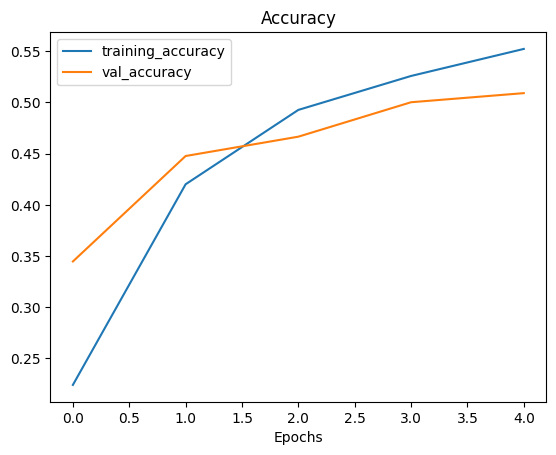

In [14]:
plot_loss_curves(history_0)

# Fine-Tuning

In [15]:
model_0_best_model = model_0.layers[2]

In [16]:
model_0_best_model.trainable=False

In [17]:
for layer in(model_0_best_model.layers[-5:]):
  layer.trainable=True

In [18]:
for layer_number, layer in enumerate(model_0_best_model.layers):
  print(layer_number,'|',layer.name,'|',layer.trainable)

0 | input_layer | False
1 | rescaling | False
2 | normalization | False
3 | stem_conv | False
4 | stem_bn | False
5 | stem_activation | False
6 | block1a_project_conv | False
7 | block1a_project_bn | False
8 | block1a_project_activation | False
9 | block2a_expand_conv | False
10 | block2a_expand_bn | False
11 | block2a_expand_activation | False
12 | block2a_project_conv | False
13 | block2a_project_bn | False
14 | block2b_expand_conv | False
15 | block2b_expand_bn | False
16 | block2b_expand_activation | False
17 | block2b_project_conv | False
18 | block2b_project_bn | False
19 | block2b_drop | False
20 | block2b_add | False
21 | block3a_expand_conv | False
22 | block3a_expand_bn | False
23 | block3a_expand_activation | False
24 | block3a_project_conv | False
25 | block3a_project_bn | False
26 | block3b_expand_conv | False
27 | block3b_expand_bn | False
28 | block3b_expand_activation | False
29 | block3b_project_conv | False
30 | block3b_project_bn | False
31 | block3b_drop | False
32 

In [19]:
model_0.compile(loss='categorical_crossentropy',
                optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                metrics=['accuracy'])

In [20]:
checkpoint_path = "101_classes_10_percent_data_model_checkpoint.weights.h5"
checkpoint_callback=tf.keras.callbacks.ModelCheckpoint(checkpoint_path,
                                                       save_weights_only=True,
                                                       monitor='val_accuracy',
                                                       save_best_only=True)

In [21]:
fine_tune_epochs=10

history_all_classes_10_percent_fine_tune=model_0.fit(train_data_all_10_percent,
                                                     epochs=fine_tune_epochs,
                                                     steps_per_epoch=int(len(train_data_all_10_percent)),
                                                     validation_data=test_data_all_10_percent,
                                                     validation_steps=(0.25 * len(test_data_all_10_percent)),
                                                       initial_epoch=history_0.epoch[-1],
                                                       callbacks=[checkpoint_callback])

Epoch 5/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.5660 - loss: 1.9293

TypeError: 'float' object cannot be interpreted as an integer

In [ ]:
for layer in model_0.layers:
  print(layer.name, layer.trainable)

In [ ]:
for layer_number, layer in enumerate(base_model.layers):
  print(layer_number, layer.name, layer.trainable)

In [ ]:
results_all_classes_10_percent_fine_tune = model_0.evaluate(test_data)
results_all_classes_10_percent_fine_tune


In [ ]:
plot_loss_curves(history_all_classes_10_percent_fine_tune)

In [ ]:
def compare_historys(original_history, new_history, initial_epochs=5):
    """
    Compares two model history objects.
    """
    # Get original history measurements
    acc = original_history.history["accuracy"]
    loss = original_history.history["loss"]

    print(len(acc))

    val_acc = original_history.history["val_accuracy"]
    val_loss = original_history.history["val_loss"]

    # Combine original history with new history
    total_acc = acc + new_history.history["accuracy"]
    total_loss = loss + new_history.history["loss"]

     total_val_acc = val_acc + new_history.history["val_accuracy"]
    total_val_loss = val_loss + new_history.history["val_loss"]

    print(len(total_acc))
    print(total_acc)

    # Make plots
    plt.figure(figsize=(8, 8))
    plt.subplot(2, 1, 1)
    plt.plot(total_acc, label='Training Accuracy')
    plt.plot(total_val_acc, label='Validation Accuracy')
    plt.plot([initial_epochs-1, initial_epochs-1],
              plt.ylim(), label='Start Fine Tuning') # reshift plot around epochs
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(2, 1, 2)
    plt.plot(total_loss, label='Training Loss')
    plt.plot(total_val_loss, label='Validation Loss')
    plt.plot([initial_epochs-1, initial_epochs-1],
              plt.ylim(), label='Start Fine Tuning') # reshift plot around epochs
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.xlabel('epoch')
    plt.show()

In [ ]:
compare_historys(original_history=history_0,
                 new_history=history_all_classes_10_percent_fine_tune,
                 initial_epochs=5)